In [2]:
import numpy as np
import torch
import torch.nn as nn
import torchvision.datasets as datasets
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
random_state = 42
torch.manual_seed(random_state)
from torchvision import transforms
from torch.nn import init

In [3]:
transform = transforms.Compose([transforms.ToTensor()])
train_set = datasets.MNIST(
    root = 'data',
    download = True,
    train = True,
    transform = transform
)
test_set = datasets.MNIST(
    root = 'data',
    download = True,
    train = False,
    transform = transform
)
trainloader = DataLoader(train_set, batch_size = 1024, num_workers = 10, shuffle = True)
testloader = DataLoader(test_set, batch_size = 1024, num_workers = 10, shuffle = True)

In [4]:
from torch.nn.modules.pooling import MaxPool2d
class NeuralNetwork(nn.Module):
  def __init__(self):
    super(NeuralNetwork, self).__init__()

    self.conv_layer1 = nn.Sequential(
        nn.Conv2d(in_channels = 1, out_channels = 64, kernel_size = 3, padding = 'same'),
        nn.ReLU(),
        nn.MaxPool2d(2, 2)
    )
    self.conv_layer2 = nn.Sequential(
        nn.Conv2d(in_channels = 64, out_channels = 128, kernel_size = 3, padding = 'same'),
        nn.ReLU(),
        nn.MaxPool2d(2, 2)
    )
    self.flatten = nn.Flatten()
    self.fc_layer1 = nn.Sequential(
        nn.Linear(128 * 7 * 7, 512),
        nn.ReLU()
    )
    self.fc_layer2 = nn.Sequential(
        nn.Linear(512, 10)
    )
    for module in self.modules():
      if isinstance(module, (nn.Linear, nn.Conv2d)):
        init.xavier_normal_(module.weight)
        if module.bias is not None:
          init.zeros_(module.bias)
  def forward(self, x):
    x = self.conv_layer1(x)
    x = self.conv_layer2(x)
    x = self.flatten(x)
    x = self.fc_layer1(x)
    out = self.fc_layer2(x)
    return out.squeeze(1)
model = NeuralNetwork().to(device)
print(model)

NeuralNetwork(
  (conv_layer1): Sequential(
    (0): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_layer2): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc_layer1): Sequential(
    (0): Linear(in_features=6272, out_features=512, bias=True)
    (1): ReLU()
  )
  (fc_layer2): Sequential(
    (0): Linear(in_features=512, out_features=10, bias=True)
  )
)


<h1>Train Model</h1>

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr = 1e-5)
epochs = 10
losses_final = []
for epoch in range(epochs):
  model.train()
  losses = 0.0
  total = 0.0
  correct = 0
  for X_samples, y_samples in trainloader:
    X_samples = X_samples.to(device)
    y_samples = y_samples.to(device)

    # forward

    outputs = model(X_samples)
    loss = criterion(outputs, y_samples)

    # backward

    optimizer.zero_grad()

    loss.backward()

    # update parameters
    optimizer.step()
    _, predicted = torch.max(outputs, dim = 1)
    losses += loss.item() * X_samples.size(0)
    total += X_samples.size(0)
    correct += (predicted == y_samples).sum().item()
  train_losses = losses / total
  accuracy = correct / total * 100
  losses_final.append(train_losses)
  print(
      f'Epoch: {epoch + 1} | ',
      f'Loss: {loss:.4f} | ',
      f'Accuracy: {accuracy:.2 |}% '
  )


Epoch: 1 |  Loss: 2.1575 |  Accuracy: 43.92% | 
Epoch: 2 |  Loss: 1.8747 |  Accuracy: 73.83% | 
Epoch: 3 |  Loss: 1.5293 |  Accuracy: 77.28% | 
Epoch: 4 |  Loss: 1.1603 |  Accuracy: 79.59% | 
Epoch: 5 |  Loss: 0.9120 |  Accuracy: 81.68% | 
Epoch: 6 |  Loss: 0.7204 |  Accuracy: 83.75% | 
Epoch: 7 |  Loss: 0.6155 |  Accuracy: 85.52% | 
Epoch: 8 |  Loss: 0.5462 |  Accuracy: 87.02% | 
Epoch: 9 |  Loss: 0.4818 |  Accuracy: 88.22% | 
Epoch: 10 |  Loss: 0.4080 |  Accuracy: 89.17% | 


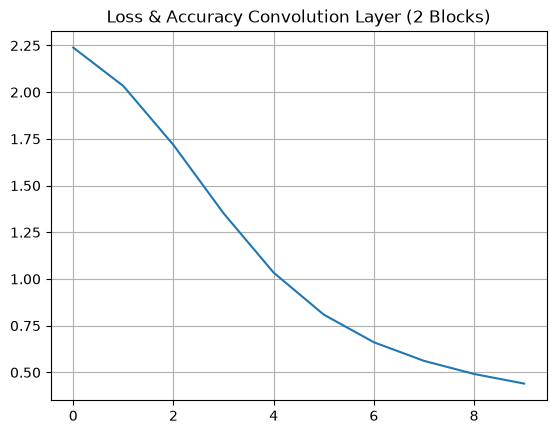

In [6]:
import matplotlib.pyplot as plt
plt.plot(losses_final)
plt.title('Loss & Accuracy Convolution Layer (2 Blocks)')
plt.grid(True)
plt.show()

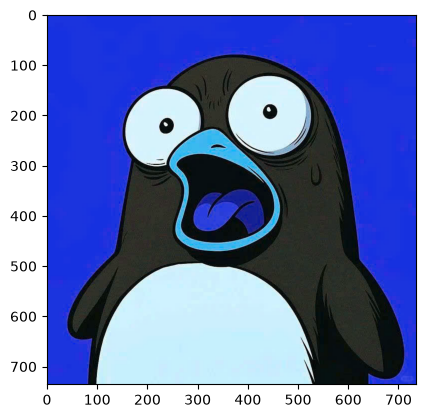

In [7]:
import cv2
image = cv2.imread('data/bird.jpg')
plt.imshow(image)

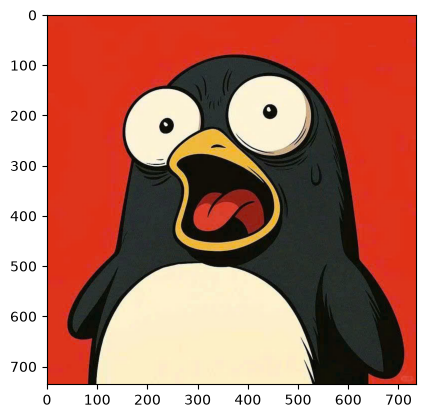

In [8]:
image = image[:, : , (2, 1, 0)]
plt.imshow(image)

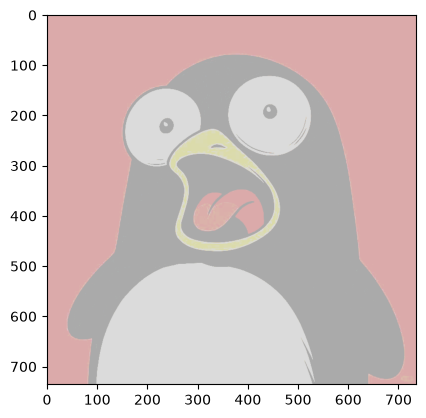

In [15]:
import numpy as np

def increase_brightness_add(img, value=20):
    img = np.where(img + value > 255, 255, img + value)
    return img
image = increase_brightness_add(image)
plt.imshow(image)

In [17]:
for rows in image:
    for cols in rows:
        for c in cols:
            print(c, end = ' ')
        print()
    print()

219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 
219 170 170 